# Operator Learning on the poisson model
1. The poisson model and numerical solver
2. Generating samples for the initial condition (via GP)
3. Train a RBNO

## 1. The poisson model and numerical solver

L∞ error: 8.223e-05


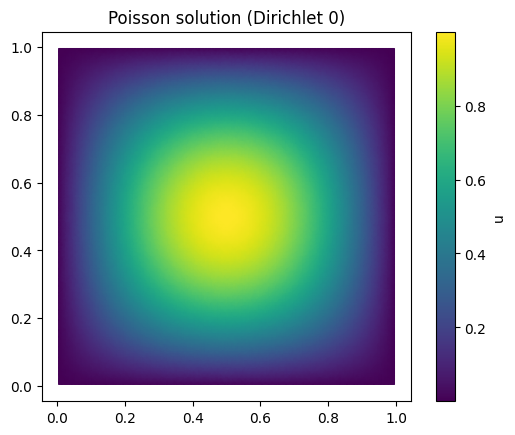

In [3]:
from fipy import Grid2D, CellVariable, DiffusionTerm, numerix as np
import numpy as onp
import matplotlib.pyplot as plt

N = 100
L = 1.0
dx = L / N
mesh = Grid2D(nx=N, ny=N, dx=dx, dy=dx)

u = CellVariable(name="u", mesh=mesh, value=0.0)
u.constrain(0.0, where=mesh.exteriorFaces)

xc, yc = mesh.cellCenters
f = 2 * np.pi**2 * np.sin(np.pi*xc) * np.sin(np.pi*yc)
f_cv = CellVariable(mesh=mesh, value=f)

eq = DiffusionTerm(var=u) == -f_cv
eq.solve(var=u)

u_exact = np.sin(np.pi*xc) * np.sin(np.pi*yc)
err_Linf = onp.max(onp.abs(u.value - u_exact))
print(f"L∞ error: {err_Linf:.3e}")

plt.figure()
plt.tripcolor(xc, yc, u.value, shading="gouraud")
plt.colorbar(label="u")
plt.gca().set_aspect("equal", adjustable="box")
plt.title("Poisson solution (Dirichlet 0)")
plt.show()



In [5]:
print(f_cv.shape)

(10000,)


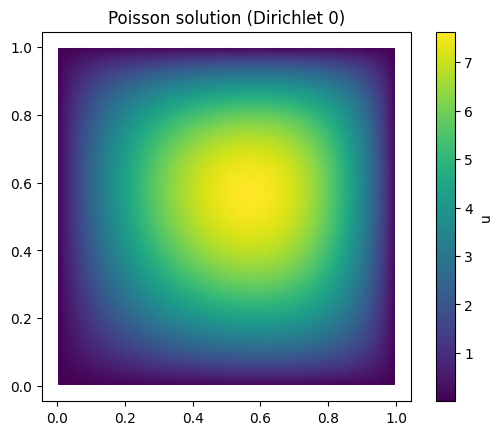

In [7]:
u = CellVariable(name="u", mesh=mesh, value=0.0)
u.constrain(0.0, where=mesh.exteriorFaces)

xc, yc = mesh.cellCenters
f = 100*xc + 100 * yc
f_cv = CellVariable(mesh=mesh, value=f)

eq = DiffusionTerm(var=u) == -f_cv
eq.solve(var=u)


plt.figure()
plt.tripcolor(xc, yc, u.value, shading="gouraud")
plt.colorbar(label="u")
plt.gca().set_aspect("equal", adjustable="box")
plt.title("Poisson solution (Dirichlet 0)")
plt.show()

## 2. Generate samples for initial condition of the problem
To generate samples, we take a Gaussian process.

In [9]:
from __future__ import annotations
from dataclasses import dataclass
from functools import cached_property
from typing import Tuple

import jax
import jax.numpy as jnp
from jaxtyping import Float, Array

# --- stability: 64-bit helps Cholesky on larger grids ---
jax.config.update("jax_enable_x64", True)

@dataclass
class Gaussian:
    mu: Float[Array, "N"]
    Sigma: Float[Array, "N N"]
    jitter: float = 1e-6

    @cached_property
    def L(self) -> Float[Array, "N N"]:
        n = self.Sigma.shape[0]
        # enforce symmetry (tiny fp errors can hurt Cholesky)
        S = 0.5 * (self.Sigma + self.Sigma.T)
        return jnp.linalg.cholesky(S + self.jitter * jnp.eye(n, dtype=S.dtype))

    def sample(self, key: jax.random.KeyArray, num_samples: int = 1
               ) -> Float[Array, "num_samples N"]:
        n = self.mu.shape[0]
        z = jax.random.normal(key, shape=(num_samples, n), dtype=self.mu.dtype)
        return self.mu + z @ self.L.T


def rbf_kernel(
    X: Float[Array, "N 2"], Y: Float[Array, "M 2"],
    variance: float = 1.0, lengthscales: Tuple[float, float] = (0.2, 0.2),
    dtype=jnp.float64
) -> Float[Array, "N M"]:
    ℓx, ℓy = lengthscales
    Xs = X / jnp.array([ℓx, ℓy], dtype=dtype)
    Ys = Y / jnp.array([ℓx, ℓy], dtype=dtype)
    diff = Xs[:, None, :] - Ys[None, :, :]
    sqdist = jnp.sum(diff * diff, axis=-1)
    return jnp.asarray(variance, dtype=dtype) * jnp.exp(-0.5 * sqdist)


def sample_gp_on_grid(
    key: jax.random.KeyArray,
    nx: int = 80, ny: int = 80,
    xlim=(0.0, 1.0), ylim=(0.0, 1.0),
    variance: float = 1.0, lengthscales=(0.15, 0.25),
    jitter: float = 1e-5, num_samples: int = 1,
    dtype=jnp.float64
):
    xs = jnp.linspace(xlim[0], xlim[1], nx, dtype=dtype)
    ys = jnp.linspace(ylim[0], ylim[1], ny, dtype=dtype)
    Xg, Yg = jnp.meshgrid(xs, ys, indexing="xy")       # (ny, nx)
    XY = jnp.stack([Xg.ravel(), Yg.ravel()], axis=-1)  # (N,2), N=nx*ny

    K = rbf_kernel(XY, XY, variance=variance, lengthscales=lengthscales, dtype=dtype)
    mu = jnp.zeros(K.shape[0], dtype=dtype)
    gp = Gaussian(mu=mu, Sigma=K, jitter=jitter)

    key, sub = jax.random.split(key)
    samples_flat = gp.sample(sub, num_samples=num_samples)         # (S, N)
    samples_img = samples_flat.reshape(num_samples, ny, nx)        # (S, ny, nx)
    return samples_img, xs, ys


In [10]:
# Plot of a gp sample

import numpy as onp
import matplotlib.pyplot as plt

key = jax.random.PRNGKey(356)  # <-- correct key ctor

min: -4.3930149033128805 max: 4.923566514002104 std: 2.1634213007129337 has_nan: False


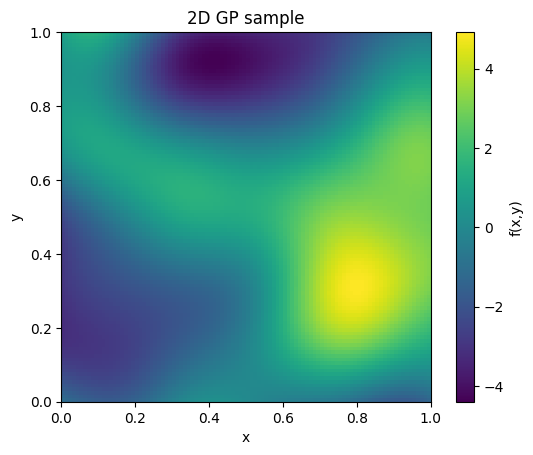

In [11]:
samples, xs, ys = sample_gp_on_grid(
    key, nx=N, ny=N,
    variance=5.0, lengthscales=(0.2, 0.2),
    jitter=1e-5, num_samples=1
)
s0 = onp.array(samples[2])  # to NumPy for plotting
print("min:", onp.nanmin(s0), "max:", onp.nanmax(s0), "std:", onp.nanstd(s0),
          "has_nan:", onp.isnan(s0).any())

# simplest, robust visualization:
plt.figure()
plt.imshow(s0, origin="lower", extent=[float(xs[0]), float(xs[-1]), float(ys[0]), float(ys[-1])], aspect="equal")
plt.colorbar(label="f(x,y)")
plt.title("2D GP sample")
plt.xlabel("x"); plt.ylabel("y")
plt.show()

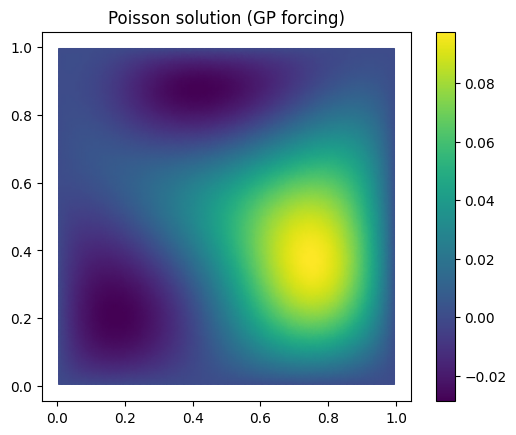

In [13]:
# s0 is shape (N, N). Flatten x-fastest to match FiPy cell order.
s_flat = onp.asarray(s0).ravel(order="C")              # length = N*N
assert s_flat.size == mesh.numberOfCells

f_cv = CellVariable(mesh=mesh, value=s_flat)

u = CellVariable(name="u", mesh=mesh, value=0.0)
u.constrain(0.0, where=mesh.exteriorFaces)
eq = DiffusionTerm(var=u) == -f_cv
eq.solve(var=u)

# Plot
plt.figure()
plt.tripcolor(*mesh.cellCenters, u.value, shading="gouraud")
plt.colorbar(); plt.gca().set_aspect("equal", adjustable="box")
plt.title("Poisson solution (GP forcing)")
plt.show()

### Generate Dataset
We generate the Training data by sampling the initial condition from a Gaussian process and then solve the pde numerically

In [15]:
num_samples = 1000
frac_train = 0.7
solution = np.zeros(shape=(num_samples,N,N))
samples, xs, ys = sample_gp_on_grid(
    key, nx=N, ny=N,
    variance=5.0, lengthscales=(0.1, 0.1),
    jitter=1e-5, num_samples=num_samples
)
for i in range(len(samples)):
    s = onp.array(samples[i])  # to NumPy for plotting
    # s0 is shape (N, N). Flatten x-fastest to match FiPy cell order.
    s_flat = onp.asarray(s).ravel(order="C")              # length = N*N
    assert s_flat.size == mesh.numberOfCells

    f_cv = CellVariable(mesh=mesh, value=s_flat)

    u = CellVariable(name="u", mesh=mesh, value=0.0)
    u.constrain(0.0, where=mesh.exteriorFaces)
    eq = DiffusionTerm(var=u) == -f_cv
    eq.solve(var=u)
    u_grid = u.value.reshape((N, N), order="C")  # shape back to grid
    solution[i] = u_grid
    

## 3. Train a FNO on the Dataset

In [19]:
# fno2d_train.py
from __future__ import annotations
import math
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader, random_split
from torch.nn import BatchNorm2d



In [50]:
# -----------------------------
# Dataset / Normalization
# -----------------------------
class GridPairDataset(Dataset):
    def __init__(self, X, Y, add_xy=True, normalize=True):
        assert X.shape == Y.shape and X.ndim == 3, "Expect (B, N, N)"
        self.X = torch.from_numpy(X)
        self.Y = torch.from_numpy(Y)
        self.add_xy = add_xy
        self.normalize = normalize

        # Stats for normalization (per-dataset scalar)
        if self.normalize:
            self.x_mean = self.X.mean()
            self.x_std  = self.X.std().clamp_min(1e-6)
            self.y_mean = self.Y.mean()
            self.y_std  = self.Y.std().clamp_min(1e-6)
        else:
            self.x_mean = self.x_std = self.y_mean = self.y_std = None

        # Pre-build positional grid (x,y) in [0,1]x[0,1]
        N = X.shape[1]
        xs = torch.linspace(0, 1, N)
        ys = torch.linspace(0, 1, N)
        Xg, Yg = torch.meshgrid(xs, ys, indexing="xy")
        self.xy = torch.stack([Xg, Yg], dim=0)  # (2, N, N)

    def __len__(self):
        return self.X.shape[0]
    
    def __shape__(self):
        return self.__shape__


    def __getitem__(self, idx):
        u0 = self.X[idx]  # (N,N)
        y  = self.Y[idx]  # (N,N)

        if self.normalize:
            u0 = (u0 - self.x_mean) / self.x_std
            y  = (y  - self.y_mean) / self.y_std

        u0 = u0.unsqueeze(0)  # (1,N,N)
        if self.add_xy:
            x_in = torch.cat([u0, self.xy], dim=0)  # (3,N,N): [u0, x, y]
        else:
            x_in = u0  # (1,N,N)

        return x_in, y.unsqueeze(0)  # input (C_in,N,N), target (1,N,N)
    def train_val_split(self, val_ratio=0.2, seed=None):
        """
        Split dataset into train/validation subsets.
        
        Args:
            val_ratio (float): Fraction of data to use for validation.
            seed (int, optional): Random seed for reproducibility.
        
        Returns:
            train_ds, val_ds (torch.utils.data.Dataset, torch.utils.data.Dataset)
        """
        n_total = len(self)
        n_val = int(n_total * val_ratio)
        n_train = n_total - n_val

        g = torch.Generator()
        if seed is not None:
            g.manual_seed(seed)

        train_ds, val_ds = random_split(self, [n_train, n_val], generator=g)
        return train_ds, val_ds




In [52]:
X, Y = onp.array(samples),onp.array(solution)
ds = GridPairDataset(X, Y, add_xy=True,  normalize=True)
train_ds, val_ds = ds.train_val_split(val_ratio=(1 - frac_train), seed=0)

import torch

# --- POD basis on the *normalized* targets ---
Y_all = ds.Y  # (B, N, N)
Y_norm = (Y_all - ds.y_mean) / ds.y_std
B, N, _ = Y_norm.shape
Y_mat = Y_norm.reshape(B, N * N)                   # snapshots as rows

# SVD: Y_mat ≈ U S Vh ; rows of Vh spatial modes
U, S, Vh = torch.linalg.svd(Y_mat, full_matrices=False)

# choose rank r
energy = (S**2).cumsum(0) / (S**2).sum()
# r = 64
r = int((energy < 0.999).sum().item())  # or just set r = 64
r = max(r, 8)                           # avoid r=0

Phi = Vh[:r, :].contiguous()            # (r, N*N) row-basis
Nside = N                               # remember grid size
print(f"RB rank r={r}, explains {float(energy[r-1])*100:.2f}% variance.")



RB rank r=36, explains 99.89% variance.


In [53]:
width=64
modes=(16,16)
n_layers=5
epochs=200

In [54]:
import torch
import torch.nn as nn

class RBNO2d(nn.Module):
    """
    Reduced-Basis Neural Operator:
      - learns coefficients a in an r-dim basis Phi
      - reconstructs u_hat = Phi^T a and reshapes to (1, N, N)
    """
    def __init__(self, in_channels=3, width=64, n_layers=3,
                 Phi=None, Nside=None):
        super().__init__()
        assert Phi is not None and Nside is not None
        self.Nside = int(Nside)
        # store basis as buffer on the right device, excluded from weight decay
        self.register_buffer("Phi", Phi)           # (r, N*N)
        r = Phi.shape[0]

        # light convolutional encoder
        layers = [nn.Conv2d(in_channels, width, kernel_size=1), nn.GELU()]
        for _ in range(n_layers):
            layers += [nn.Conv2d(width, width, kernel_size=3, padding=1), nn.GELU()]
        self.encoder = nn.Sequential(*layers)

        # global pooling + linear -> coefficients (B, r)
        self.readout = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            nn.Flatten(),
            nn.Linear(width, r)
        )

    def forward(self, x):                   # x: (B, 3, N, N) normalized
        z = self.encoder(x)                 # (B, width, N, N)
        a = self.readout(z)                 # (B, r)
        # reconstruct: u_flat = a @ Phi  where Phi=(r, N*N)
        u_flat = a @ self.Phi               # (B, N*N)
        u = u_flat.view(-1, 1, self.Nside, self.Nside)
        return u                            # still normalized

In [55]:
import torch
import torch.nn as nn

# 1) Your coefficient network, unchanged in spirit: CNN -> r coefficients
class CoeffNetCNN(nn.Module):
    def __init__(self, in_channels: int, width: int, n_layers: int, r: int):
        super().__init__()
        layers = [nn.Conv2d(in_channels, width, kernel_size=1), nn.GELU()]
        for _ in range(n_layers):
            layers += [nn.Conv2d(width, width, kernel_size=3, padding=1), nn.GELU()]
        self.encoder = nn.Sequential(*layers)
        self.readout = nn.Sequential(  # global avg pool -> linear to r
            nn.AdaptiveAvgPool2d(1),
            nn.Flatten(),
            nn.Linear(width, r)
        )

    def forward(self, x):           # x: (B, C, N, N)
        z = self.encoder(x)         # (B, W, N, N)
        c = self.readout(z)         # (B, r)
        return c

# 2) A thin wrapper that mirrors the given RBLift behavior for images
class RBLift2d(nn.Module):
    """
    Reduced-Basis Lifting wrapper for 2D grids.
    - Optional input reduction via in_cobasis (vector view of x)
    - Coefficient net maps (reduced or raw) input to coefficients c
    - Lifts with out_basis and optionally adds out_shift
    """
    def __init__(self, coeff_net: nn.Module, Nside: int,
                 in_cobasis: torch.Tensor | None = None,
                 out_basis: torch.Tensor | None = None,
                 out_shift: torch.Tensor | None = None,
                 trainable: bool = False):
        super().__init__()
        self.coeff_net = coeff_net
        self.Nside = int(Nside)

        # helpers to register param or buffer
        def _reg(name, t):
            if t is None:
                setattr(self, name, None)
            elif trainable:
                self.register_parameter(name, nn.Parameter(t))
            else:
                self.register_buffer(name, t)

        _reg("in_cobasis", in_cobasis)   # shapes (n_in, r_in) or (r_in, n_in)
        _reg("out_basis", out_basis)     # expect (n_out, r_out) for y = c @ out_basis.T
        if out_shift is not None:
            out_shift = out_shift.reshape(1, -1)   # (1, n_out)
        _reg("out_shift", out_shift)

    def _reduce(self, x_img):
        """Reduce input if in_cobasis is provided; otherwise passthrough image."""
        if self.in_cobasis is None:
            return x_img
        B = x_img.shape[0]
        x_vec = x_img.reshape(B, -1)             # (B, n_in)
        C = self.in_cobasis
        if C.is_sparse:
            if C.shape[0] == x_vec.shape[1]:     # (n_in, r)
                xr = torch.sparse.mm(C.t(), x_vec.t()).t()
            elif C.shape[1] == x_vec.shape[1]:   # (r, n_in)
                xr = torch.sparse.mm(C, x_vec.t()).t()
            else:
                raise ValueError("in_cobasis must be (n_in, r) or (r, n_in)")
        else:
            if C.shape[0] == x_vec.shape[1]:     # (n_in, r)
                xr = x_vec @ C
            elif C.shape[1] == x_vec.shape[1]:   # (r, n_in)
                xr = x_vec @ C.t()
            else:
                raise ValueError("in_cobasis must be (n_in, r) or (r, n_in)")
        # by default, feed reduced vector to coeff_net as a 1x1 "image"
        return xr.view(B, -1, 1, 1)               # (B, r_in, 1, 1)

    def forward(self, x):                         # x: (B, C, N, N)
        xin = self._reduce(x)                     # either x or reduced x (as 1x1)
        c = self.coeff_net(xin)                   # (B, r_out)

        if self.out_basis is not None:
            # out_basis expected (n_out, r_out)
            if self.out_basis.is_sparse:
                y = torch.sparse.mm(self.out_basis, c.t()).t()   # (B, n_out)
            else:
                y = c @ self.out_basis.t()                       # (B, n_out)
        else:
            y = c

        if self.out_shift is not None:
            y = y + self.out_shift                               # broadcast add

        # reshape to image if n_out == N^2
        n_out = y.shape[-1]
        if n_out == self.Nside * self.Nside:
            y = y.view(-1, 1, self.Nside, self.Nside)
        return y

# 3) How to instantiate it from your current SVD basis
# You currently have Phi with shape (r, N*N). RBLift expects (n_out, r), so pass Phi.T
# (Optionally pass ds.y_mean.flatten() as out_shift if you want to add back the mean.)
def build_rb_model(Phi, N, in_channels=3, width=64, n_layers=3, trainable=False, out_shift=None):
    r = Phi.shape[0]
    coeff_net = CoeffNetCNN(in_channels=in_channels, width=width, n_layers=n_layers, r=r)
    model = RBLift2d(
        coeff_net=coeff_net,
        Nside=N,
        in_cobasis=None,                 # optionally give PCA of inputs here
        out_basis=Phi.T.contiguous(),    # (N*N, r)
        out_shift=out_shift,             # e.g., None (you already normalized Y)
        trainable=trainable
    )
    return model


### Training loop

In [78]:
# -----------------------------
# Training loop
# -----------------------------
def train_rbno2d(
    train_ds: Dataset,
    val_ds: Dataset,
    epochs=50,
    batch_size=8,
    lr=1e-5,
    width=16,
    modes=(12,12),
    n_layers=3,
    device=None,
    wd = 1e-6
):
    device = device or ("mps" if torch.backends.mps.is_available() else "cpu")
    print(f"Using device: {device}")

    train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True, num_workers=0)
    val_loader   = DataLoader(val_ds,   batch_size=batch_size, shuffle=False, num_workers=0)

    # model = RBNO2d(
    #             in_channels=3, width=width, n_layers=n_layers,
    #             Phi=Phi.to(device, dtype=torch.float32),
    #             Nside=N
    #         ).to(device)

    rbno = RBNO2d(in_channels=3, width=width, n_layers=n_layers,
              Phi=Phi.to(device, torch.float32), Nside=N).to(device)

    coeff_net = CoeffNetCNN(in_channels=3, width=width, n_layers=n_layers, r=Phi.shape[0])
    rblift = RBLift2d(coeff_net=coeff_net, Nside=N, out_basis=Phi.T.contiguous().to(device, torch.float32)).to(device)
    
    opt_rbno  = torch.optim.Adam(rbno.parameters(),  lr=1e-3, weight_decay=1e-6)
    opt_rblft = torch.optim.Adam(rblift.parameters(), lr=1e-3, weight_decay=1e-6)

    
    # opt = torch.optim.Adam(model.parameters(), lr=lr,weight_decay=wd)
    # scheduler = torch.optim.lr_scheduler.StepLR(opt,step_size=15, gamma=0.01)
    scheduler_rbno = torch.optim.lr_scheduler.StepLR(opt_rbno,step_size=15, gamma=0.01)
    scheduler_rblft = torch.optim.lr_scheduler.StepLR(opt_rblft,step_size=15, gamma=0.01)
    loss_fn = nn.MSELoss()

    best_val_rbno = math.inf
    best_val_rblft = math.inf
    for ep in range(1, epochs+1):
        rbno.train(); rblift.train()
        tr_rbno = tr_rblft = 0.0
        for x, y in train_loader:
            x = x.to(device, torch.float32); y = y.to(device, torch.float32)
    
            # RBNO2d step
            opt_rbno.zero_grad()
            y_hat_rbno = rbno(x)
            loss_rbno = loss_fn(y_hat_rbno, y)  # + lambda * MSE(a_rbno, A_true_batch) if you add coef targets
            loss_rbno.backward(); opt_rbno.step()
            tr_rbno += loss_rbno.item() * x.size(0)
    
            # RBLift2d step
            opt_rblft.zero_grad()
            y_hat_rblft = rblift(x)
            loss_rblft = loss_fn(y_hat_rblft, y)
            loss_rblft.backward(); opt_rblft.step()
            tr_rblft += loss_rblft.item() * x.size(0)
    
        # eval both
        rbno.eval(); rblift.eval()
        with torch.no_grad():
            va_rbno = va_rblft = 0.0
            for x, y in val_loader:
                x = x.to(device, torch.float32); y = y.to(device, torch.float32)
                y1 = rbno(x)
                y2 = rblift(x)
                va_rbno  += loss_fn(y1, y).item() * x.size(0)
                va_rblft += loss_fn(y2, y).item() * x.size(0)
        print(f"[{ep:03d}] RBNO train {tr_rbno/len(train_ds):.3e} val {va_rbno/len(val_ds):.3e} | "
              f"RBLift train {tr_rblft/len(train_ds):.3e} val {va_rblft/len(val_ds):.3e}")
        
        va_rbno /= len(val_loader.dataset)
        va_rblft /= len(val_loader.dataset)

        if va_rbno < best_val_rbno:
            best_val_rbno = va_rbno
            torch.save(rbno.state_dict(), "rbno2d_best.pt")
        scheduler_rbno.step()

        if va_rblft < best_val_rblft:
            best_val_rblft = va_rblft
            torch.save(rblift.state_dict(), "rblift_best.pt")
        scheduler_rblft.step()


    # for ep in range(1, epochs+1):
    #     model.train()
    #     tr_loss = 0.0
    #     for x, y in train_loader:
    #         x = x.to(device, dtype=torch.float32)   # (B, 3, N, N)
    #         y = y.to(device, dtype=torch.float32)   # (B, 1, N, N)

    #         opt.zero_grad()
    #         pred = model(x)
    #         loss = loss_fn(pred, y)
    #         loss.backward()
    #         opt.step()
    #         tr_loss += loss.item() * x.size(0)

    #     tr_loss /= len(train_loader.dataset)

    #     model.eval()
    #     va_loss = 0.0
    #     with torch.no_grad():
    #         for x, y in val_loader:
    #             x = x.to(device, dtype=torch.float32)
    #             y = y.to(device, dtype=torch.float32)
    #             pred = model(x)
    #             va_loss += loss_fn(pred, y).item() * x.size(0)
    #     va_loss /= len(val_loader.dataset)

    #     if va_loss < best_val:
    #         best_val = va_loss
    #         torch.save(model.state_dict(), "rbno2d_best.pt")
    #     scheduler.step()
    #     print(f"[{ep:03d}/{epochs}] train {tr_loss:.4e}  val {va_loss:.4e}  (best {best_val:.4e}) lr: {scheduler.get_last_lr()[0]:.2e}")

    print("Training complete. Best model saved to rbno2d_best.pt")
    return rbno, rblift




    

In [ ]:
rbno, rblift = train_rbno2d(
        train_ds, val_ds,
        epochs=epochs, batch_size=32, lr=1e-3,
        width=width, modes=modes, n_layers=n_layers,wd = 1e-6
    )

Using device: cpu
[001] RBNO train 9.157e-01 val 6.588e-01 | RBLift train 9.292e-01 val 8.458e-01
[002] RBNO train 5.638e-01 val 4.602e-01 | RBLift train 6.098e-01 val 4.815e-01
[003] RBNO train 5.319e-01 val 5.157e-01 | RBLift train 5.203e-01 val 5.973e-01
[004] RBNO train 5.144e-01 val 5.377e-01 | RBLift train 4.901e-01 val 5.073e-01
[005] RBNO train 5.381e-01 val 4.610e-01 | RBLift train 4.907e-01 val 4.582e-01
[006] RBNO train 5.117e-01 val 4.509e-01 | RBLift train 4.756e-01 val 4.704e-01
[007] RBNO train 4.736e-01 val 4.478e-01 | RBLift train 4.767e-01 val 4.465e-01
[008] RBNO train 4.685e-01 val 4.487e-01 | RBLift train 4.665e-01 val 4.441e-01
[009] RBNO train 4.772e-01 val 4.567e-01 | RBLift train 4.778e-01 val 4.378e-01
[010] RBNO train 4.674e-01 val 4.547e-01 | RBLift train 4.675e-01 val 4.351e-01
[011] RBNO train 4.645e-01 val 4.442e-01 | RBLift train 4.539e-01 val 4.382e-01
[012] RBNO train 4.784e-01 val 4.430e-01 | RBLift train 4.636e-01 val 4.530e-01
[013] RBNO train 4.820

### Evaluation

In [36]:

# --- load the best model ---
device = "mps" if torch.backends.mps.is_available() else "cpu"

model = RBNO2d(
                in_channels=3, width=width, n_layers=n_layers,
                Phi=Phi.to(device, dtype=torch.float32),
                Nside=N
            ).to(device)

model.load_state_dict(torch.load("rbno2d_best.pt", map_location=device))
model = model.to(device)
model.eval()

# --- evaluation ---
val_loader = DataLoader(val_ds, batch_size=8, shuffle=False)
loss_fn = nn.MSELoss(reduction="mean")

total_loss = 0.0
num_samples = 0
with torch.no_grad():
    for x, y in val_loader:
        x = x.to(device, dtype=torch.float32)  # (B,3,N,N)
        y = y.to(device, dtype=torch.float32)  # (B,1,N,N)
        pred = model(x)

        # accumulate MSE
        loss = loss_fn(pred, y).item()
        total_loss += loss * x.size(0)
        num_samples += x.size(0)

avg_mse = total_loss / num_samples
rmse = avg_mse ** 0.5
print(f"Validation MSE:  {avg_mse:.4e}")
print(f"Validation RMSE: {rmse:.4e}")

C:\Users\dvod\AppData\Local\Temp\ipykernel_5008\1662962786.py:10: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load("rbno2d_best.pt", map_locati

Validation MSE:  4.1803e-01
Validation RMSE: 6.4655e-01


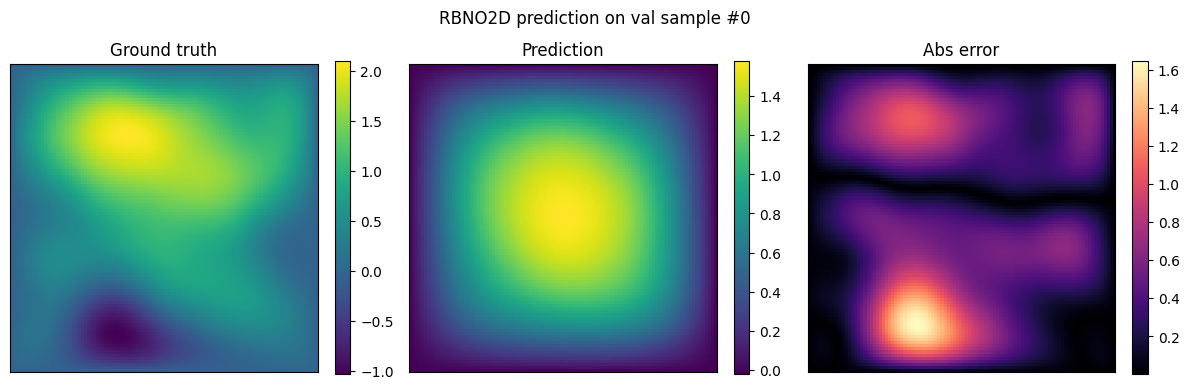

In [37]:
# --- pick one sample from val_ds ---
idx = 0  # choose which sample to visualize
x_in, y_true = val_ds[idx]      # shapes: (C_in,N,N), (1,N,N)
N = y_true.shape[-1]

x_in_t = x_in.unsqueeze(0).to(device, dtype=torch.float32)   # (1,C_in,N,N)
with torch.no_grad():
    y_pred_t = model(x_in_t)   # (1,1,N,N)

y_pred = y_pred_t.cpu().numpy()[0,0]   # (N,N)
y_true = y_true.numpy()[0]             # (N,N)

# --- plot ---
fig, axs = plt.subplots(1,3, figsize=(12,4))
im0 = axs[0].imshow(y_true, origin="lower", cmap="viridis")
axs[0].set_title("Ground truth")
plt.colorbar(im0, ax=axs[0], fraction=0.046)

im1 = axs[1].imshow(y_pred, origin="lower", cmap="viridis")
axs[1].set_title("Prediction")
plt.colorbar(im1, ax=axs[1], fraction=0.046)

im2 = axs[2].imshow(np.abs(y_pred - y_true), origin="lower", cmap="magma")
axs[2].set_title("Abs error")
plt.colorbar(im2, ax=axs[2], fraction=0.046)

for ax in axs:
    ax.set_xticks([]); ax.set_yticks([])

plt.suptitle(f"RBNO2D prediction on val sample #{idx}")
plt.tight_layout()